In [36]:
#Project 1: Customer Segmentation using K-Means
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [37]:
df = pd.read_csv("customers.csv")

print(df.head())

   CustomerID  Age  Annual_Income  Spending_Score
0           1   19          15000              39
1           2   21          15000              81
2           3   20          16000               6
3           4   23          16000              77
4           5   31          17000              40


In [38]:
print("Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(20, 4)

Missing Values:
CustomerID        0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64


In [39]:
X = df[["Age", "Annual_Income", "Spending_Score"]]

print(X.head())

   Age  Annual_Income  Spending_Score
0   19          15000              39
1   21          15000              81
2   20          16000               6
3   23          16000              77
4   31          17000              40


In [40]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.95306726 -1.36496076 -0.33504478]
 [-0.81835811 -1.36496076  0.98008426]
 [-0.88571269 -1.16996636 -1.36836045]
 [-0.68364896 -1.16996636  0.85483387]
 [-0.14481234 -0.97497197 -0.30373218]]


C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

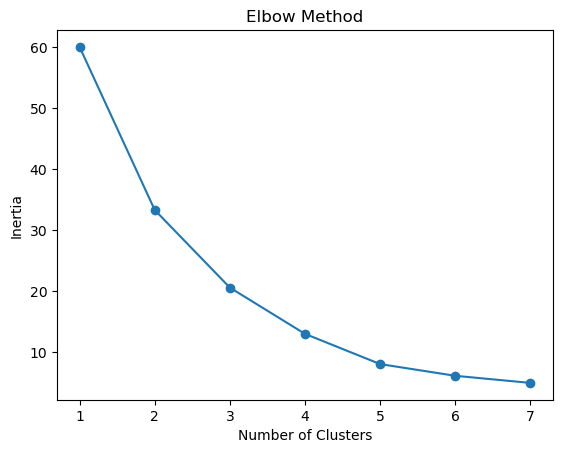

In [41]:
inertia = []

for k in range(1, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.plot(range(1, 8), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

k = 3

In [42]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df)

    CustomerID  Age  Annual_Income  Spending_Score  Cluster
0            1   19          15000              39        0
1            2   21          15000              81        0
2            3   20          16000               6        0
3            4   23          16000              77        0
4            5   31          17000              40        0
5            6   22          18000              76        0
6            7   35          18000               6        2
7            8   23          19000              94        0
8            9   64          20000               3        2
9           10   30          21000              72        0
10          11   67          22000              14        2
11          12   35          23000              99        1
12          13   58          24000              15        2
13          14   24          25000              77        1
14          15   37          26000              13        2
15          16   22          27000      

C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


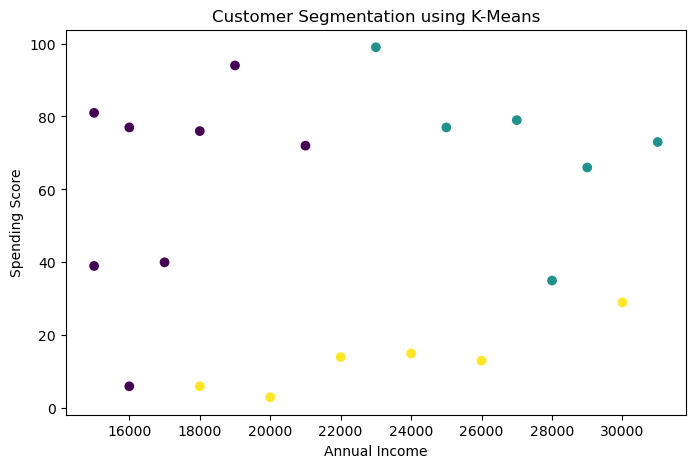

In [43]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"]
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")

plt.show()

In [44]:
score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", score)

Silhouette Score: 0.36896163259497056


In [45]:
for cluster in sorted(df["Cluster"].unique()):

    print("\nCluster:", cluster)

    print(
        df[df["Cluster"] == cluster][
            ["CustomerID", "Age", "Annual_Income", "Spending_Score"]
        ]
    )


Cluster: 0
   CustomerID  Age  Annual_Income  Spending_Score
0           1   19          15000              39
1           2   21          15000              81
2           3   20          16000               6
3           4   23          16000              77
4           5   31          17000              40
5           6   22          18000              76
7           8   23          19000              94
9          10   30          21000              72

Cluster: 1
    CustomerID  Age  Annual_Income  Spending_Score
11          12   35          23000              99
13          14   24          25000              77
15          16   22          27000              79
16          17   35          28000              35
17          18   20          29000              66
19          20   25          31000              73

Cluster: 2
    CustomerID  Age  Annual_Income  Spending_Score
6            7   35          18000               6
8            9   64          20000               3
10  

In [46]:
#Project 2: News Article Clustering System
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

In [47]:
df = pd.read_csv("news.csv")

print(df)

                                         Title    Category
0                     India wins cricket match      Sports
1         Team prepares for cricket tournament      Sports
2              Football team wins championship      Sports
3     New smartphone launched with AI features  Technology
4   Artificial intelligence changes technology  Technology
5              New computer processor released  Technology
6                Stock market reaches new high    Business
7      Company announces new business strategy    Business
8          Business market shows strong growth    Business
9    Government announces new education policy    Politics
10  New election rules announced by government    Politics
11        Political leaders discuss new policy    Politics


In [48]:
print(df.isnull().sum())

df = df.dropna()

Title       0
Category    0
dtype: int64


In [49]:
vectorizer = TfidfVectorizer(
    stop_words="english"
)

X = vectorizer.fit_transform(df["Title"])

print(X.shape)

(12, 41)


In [50]:
inertia = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    inertia.append(model.inertia_)

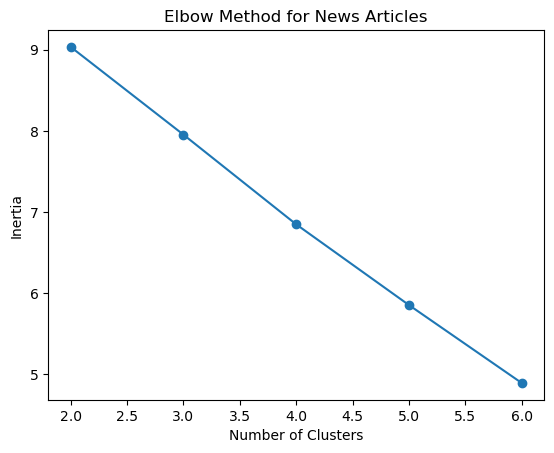

In [51]:
#Graph
plt.plot(range(2, 7), inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for News Articles")

plt.show()

In [52]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X)

print(df[["Title", "Cluster"]])

                                         Title  Cluster
0                     India wins cricket match        2
1         Team prepares for cricket tournament        2
2              Football team wins championship        2
3     New smartphone launched with AI features        1
4   Artificial intelligence changes technology        0
5              New computer processor released        1
6                Stock market reaches new high        3
7      Company announces new business strategy        1
8          Business market shows strong growth        3
9    Government announces new education policy        1
10  New election rules announced by government        1
11        Political leaders discuss new policy        1


In [53]:
score = silhouette_score(X, df["Cluster"])

print("Silhouette Score:", score)

Silhouette Score: 0.0559904763526757


In [54]:
for cluster in sorted(df["Cluster"].unique()):

    print("\n====================")
    print("Cluster:", cluster)
    print("====================")

    news = df[df["Cluster"] == cluster]

    for title in news["Title"]:
        print("-", title)


Cluster: 0
- Artificial intelligence changes technology

Cluster: 1
- New smartphone launched with AI features
- New computer processor released
- Company announces new business strategy
- Government announces new education policy
- New election rules announced by government
- Political leaders discuss new policy

Cluster: 2
- India wins cricket match
- Team prepares for cricket tournament
- Football team wins championship

Cluster: 3
- Stock market reaches new high
- Business market shows strong growth


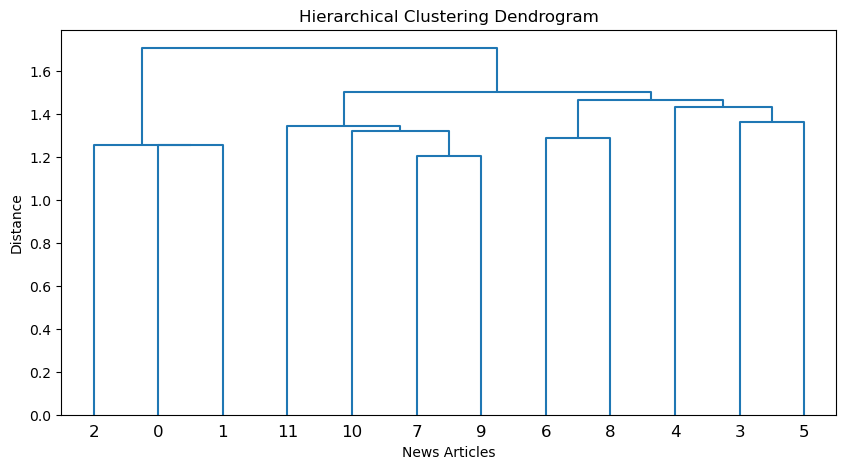

In [55]:
Z = linkage(
    X.toarray(),
    method="ward"
)

#Dendrogram
plt.figure(figsize=(10, 5))

dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("News Articles")
plt.ylabel("Distance")

plt.show()